Importing the Dependencies

In [110]:
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [111]:
# Load dataset
credit_card_data = pd.read_csv('creditcard.csv')

# Print Info
print("--- Data Info ---")
credit_card_data.info()

print("\n--- Missing Values ---")
print(credit_card_data.isnull().sum())

print("\n--- Class Distribution ---")
print(credit_card_data['Class'].value_counts())

# 0 --> Normal Transaction
# 1 --> Fraudulent Transaction

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21

In [112]:
# Separating the data
legit = credit_card_data[credit_card_data.Class == 0]
fraud = credit_card_data[credit_card_data.Class == 1]

print("Legit Shape:", legit.shape)
print("Fraud Shape:", fraud.shape)

print("\n--- Legit Amount Stats ---")
print(legit.Amount.describe())

print("\n--- Fraud Amount Stats ---")
print(fraud.Amount.describe())

print("\n--- Mean Comparison ---")
print(credit_card_data.groupby('Class').mean())

Legit Shape: (284315, 31)
Fraud Shape: (492, 31)

--- Legit Amount Stats ---
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

--- Fraud Amount Stats ---
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

--- Mean Comparison ---
               Time        V1        V2        V3        V4        V5  \
Class                                                                   
0      94838.202258  0.008258 -0.006271  0.012171 -0.007860  0.005453   
1      80746.806911 -4.771948  3.623778 -7.033281  4.542029 -3.151225   

             V6        V7        V8        V9  ...       V20       V21  \
Class                                          ...                       
0      0.002419  0.

In [113]:
# Time column drop (no role in fraud detection)
X = credit_card_data.drop(columns=['Class', 'Time'])
Y = credit_card_data['Class']

print("Features shape:", X.shape)
print("Target shape:", Y.shape)

Features shape: (284807, 29)
Target shape: (284807,)


In [114]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y, random_state=2
)

print("X Shape:", X.shape)
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

X Shape: (284807, 29)
X_train Shape: (227845, 29)
X_test Shape: (56962, 29)


In [ ]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)   

smote = SMOTE(random_state=42)
X_train_balanced, Y_train_balanced = smote.fit_resample(X_train_scaled, Y_train)

print("Balanced Training Target Distribution:")
print(Y_train_balanced.value_counts())

Balanced Training Target Distribution:
Class
0    227451
1    227451
Name: count, dtype: int64


In [116]:
# Training Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_balanced, Y_train_balanced)

print("Model trained successfully! ")

Model trained successfully! 


0 --> Normal Transaction

1 --> fraudulent transaction

In [117]:
# accuracy on training data (MUST USE SCALED DATA)
X_train_prediction = model.predict(X_train_scaled)
training_data_accuracy = accuracy_score(X_train_prediction, Y_train)
print('Accuracy on Training data : ', training_data_accuracy)

# accuracy on test data (MUST USE SCALED DATA)
X_test_prediction = model.predict(X_test_scaled)
test_data_accuracy = accuracy_score(X_test_prediction, Y_test)
print('Accuracy score on Test Data : ', test_data_accuracy)

Accuracy on Training data :  0.9736575303386074
Accuracy score on Test Data :  0.973210210315649


In [ ]:
print("=" * 60)
print("DETAILED EVALUATION ON TEST DATA (Threshold = 0.99)")
print("=" * 60)


best_threshold = 0.99
y_probs = model.predict_proba(X_test_scaled)[:, 1]
y_pred_best = (y_probs >= best_threshold).astype(int)

print(classification_report(Y_test, y_pred_best, target_names=['Normal', 'Fraud']))

print(f"Precision : {precision_score(Y_test, y_pred_best):.4f}")
print(f"Recall    : {recall_score(Y_test, y_pred_best):.4f}")
print(f"F1 Score  : {f1_score(Y_test, y_pred_best):.4f}")
print(f"ROC-AUC   : {roc_auc_score(Y_test, y_probs):.4f}")

DETAILED EVALUATION ON TEST DATA (Threshold = 0.99)
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.59      0.88      0.70        98

    accuracy                           1.00     56962
   macro avg       0.79      0.94      0.85     56962
weighted avg       1.00      1.00      1.00     56962

Precision : 0.5850
Recall    : 0.8776
F1 Score  : 0.7020
ROC-AUC   : 0.9890


In [ ]:
from sklearn.metrics import precision_recall_curve, f1_score

 
y_probs = model.predict_proba(X_test_scaled)[:, 1]


thresholds = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]

print("Threshold | Precision | Recall | F1 Score")
print("-" * 45)

for thresh in thresholds:
    
    y_pred_custom = (y_probs >= thresh).astype(int)
    
    p = precision_score(Y_test, y_pred_custom)
    r = recall_score(Y_test, y_pred_custom)
    f1 = f1_score(Y_test, y_pred_custom)
    
    print(f"   {thresh:.2f}   |   {p:.4f}  | {r:.4f} |  {f1:.4f}")

Threshold | Precision | Recall | F1 Score
---------------------------------------------
   0.50   |   0.0565  | 0.9286 |  0.1066
   0.70   |   0.1098  | 0.9286 |  0.1963
   0.80   |   0.1489  | 0.9286 |  0.2567
   0.90   |   0.2037  | 0.9082 |  0.3327
   0.95   |   0.2627  | 0.8980 |  0.4065
   0.99   |   0.5850  | 0.8776 |  0.7020


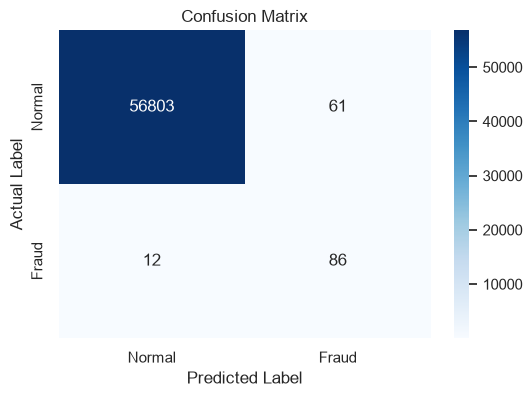

In [120]:
best_threshold = 0.99
y_pred_best = (y_probs >= best_threshold).astype(int) 

cm = confusion_matrix(Y_test, y_pred_best)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Fraud'],
            yticklabels=['Normal', 'Fraud'])
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()